In [32]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler)

from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

In [33]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/pima-indians-diabetes.data.csv", header = None)
df.head()

,0,1,2,3,4,5,6,7,8
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [34]:
columns = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']

df.columns = columns

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Note
- Here the label contains two labels
- 0 — Non-diabetic
- 1 — Diabetic

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### Note:
- some of the columns have 0 in place of Null
- example BMI, Glucose, ...
- Treat them 

In [36]:
x = df.drop(columns="Outcome")
y = df["Outcome"]

In [37]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

## Scaling

In [38]:
numerical_columns = x.select_dtypes(include = 'number')        # include = ('int','float')
numerical_columns

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


### Analysing the outliers in each of the columns using boxplot

In [39]:
for i in numerical_columns.columns:
    print(f'plt.boxplot(df["{i}"])')


plt.boxplot(df["Pregnancies"])
plt.boxplot(df["Glucose"])
plt.boxplot(df["BloodPressure"])
plt.boxplot(df["SkinThickness"])
plt.boxplot(df["Insulin"])
plt.boxplot(df["BMI"])
plt.boxplot(df["DiabetesPedigreeFunction"])
plt.boxplot(df["Age"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d381c1e50>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d381c2f00>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d33f1ffe0>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d381c3aa0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d3198c1a0>],
 'means': []}

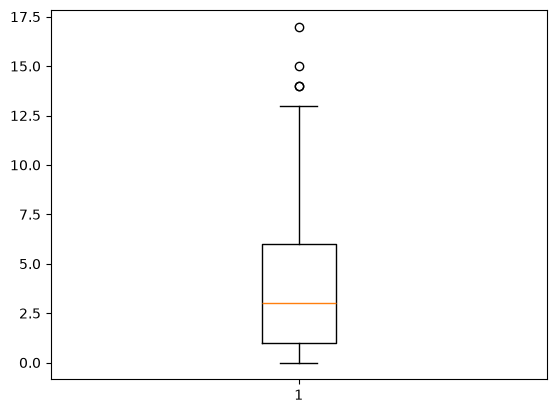

In [40]:
plt.boxplot(df["Pregnancies"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d31a397c0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d31a39d00>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d31a39580>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d31a3a0c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d31a3a360>],
 'means': []}

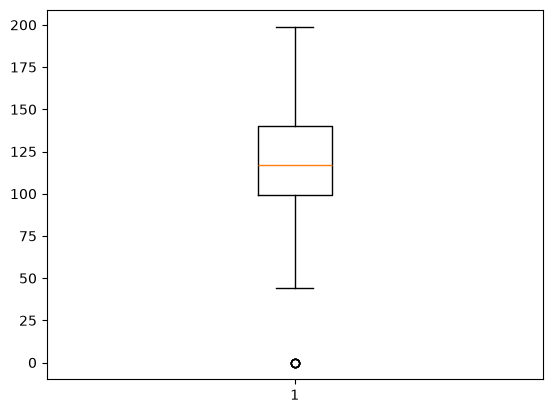

In [41]:
plt.boxplot(df["Glucose"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d31896bd0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d31896ff0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d31896990>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d31897500>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d31897770>],
 'means': []}

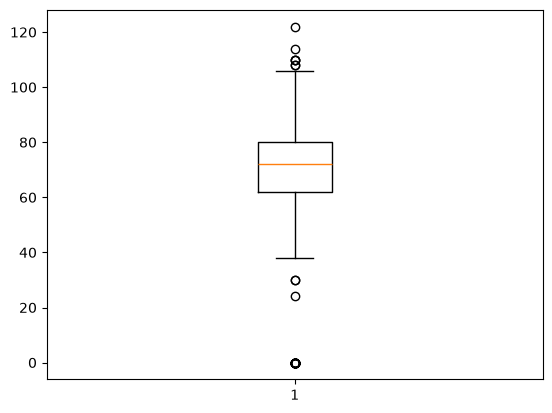

In [42]:
plt.boxplot(df["BloodPressure"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d318eea80>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d318eee70>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d318ee7e0>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d318ef380>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d318ef620>],
 'means': []}

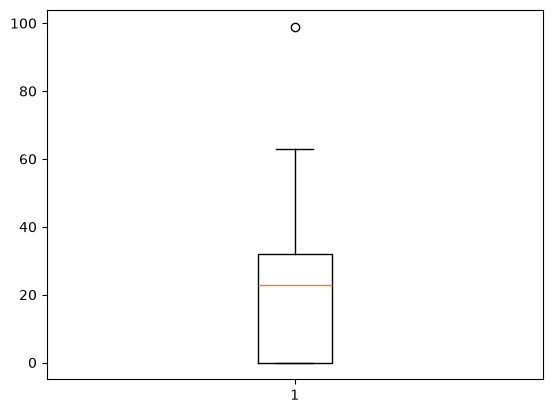

In [43]:
plt.boxplot(df["SkinThickness"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d3194e1b0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d3194e6f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d3194df40>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d3194ec30>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d3193ba70>],
 'means': []}

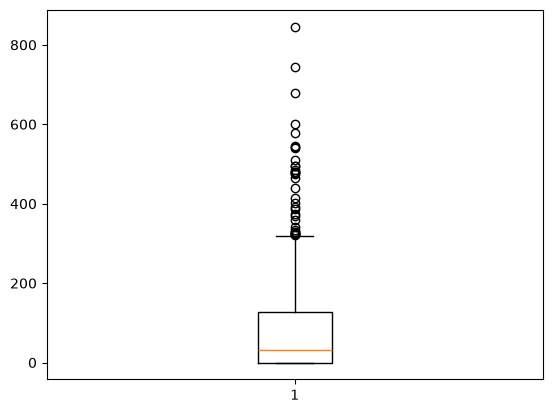

In [44]:
plt.boxplot(df["Insulin"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d317b87a0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d317b8ce0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d317b8680>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d317b9220>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d317b94c0>],
 'means': []}

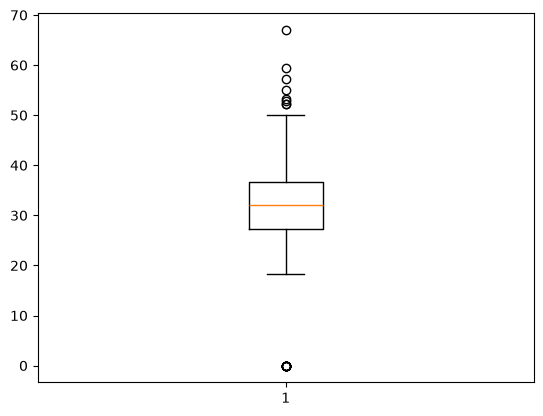

In [45]:
plt.boxplot(df["BMI"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d31810ec0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d31811400>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d31810cb0>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d318118e0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d31811b80>],
 'means': []}

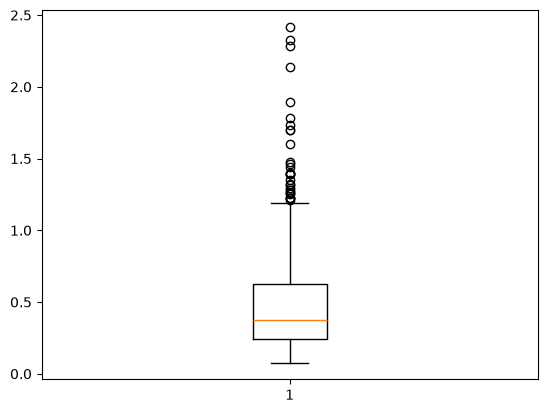

In [46]:
plt.boxplot(df["DiabetesPedigreeFunction"])


{'whiskers': [<matplotlib.lines.Line2D at 0x7d2d3184fda0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d2d316802f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d2d3184fbc0>],
 'medians': [<matplotlib.lines.Line2D at 0x7d2d31680710>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d2d316808f0>],
 'means': []}

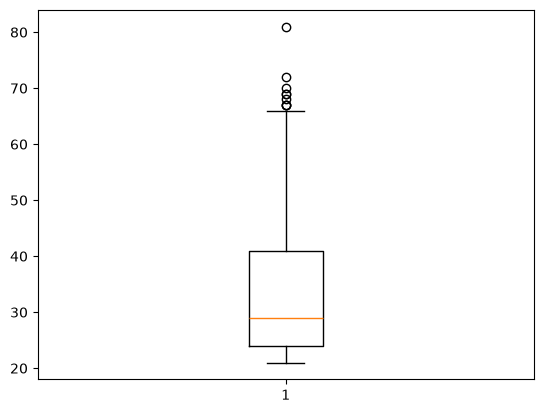

In [47]:
plt.boxplot(df["Age"])

In [48]:
columns_for_standard_scaler = ["Pregnancies","Glucose","BloodPressure","SkinThickness",'BMI','Age']
columns_for_robust_scaler = ['Insulin','DiabetesPedigreeFunction']

In [ ]:
standard_scalar = StandardScaler()
robust_scalar = RobustScaler()

In [50]:
x_train[columns_for_standard_scaler] = standard_scalar.fit_transform(x_train[columns_for_standard_scaler])
x_train[columns_for_robust_scaler] = robust_scalar.fit_transform(x_train[columns_for_robust_scaler])
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,-0.526397,-1.151398,-3.752683,-1.322774,-0.327553,-4.135256,-0.184016,-1.035940
618,1.588046,-0.276643,0.680345,0.233505,-0.327553,-0.489169,2.443251,1.487101
346,-0.828460,0.566871,-1.265862,-0.090720,0.312139,-0.424522,0.756212,-0.948939
294,-1.130523,1.254179,-1.049617,-1.322774,-0.327553,-1.303720,-0.318334,2.792122
231,0.681856,0.410665,0.572222,1.076490,2.524085,1.838121,-0.361316,1.139095


In [51]:
x_test[columns_for_standard_scaler] = standard_scalar.transform(x_test[columns_for_standard_scaler])
x_test[columns_for_robust_scaler] = robust_scalar.transform(x_test[columns_for_robust_scaler])
x_test.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
668,0.681856,-0.714020,-0.617127,0.817110,1.136802,0.260736,0.154466,0.878091
324,-0.526397,-0.276643,0.301916,0.752265,-0.327553,0.480535,-0.603089,-1.035940
624,-0.526397,-0.401608,-0.292759,-1.322774,-0.327553,-0.153005,-0.576226,-1.035940
690,1.285983,-0.432849,0.572222,-1.322774,-0.327553,-0.954627,1.298858,0.095078
473,0.983919,0.473147,1.112835,-1.322774,-0.327553,-0.269369,-0.436535,1.487101


## No need of Encoding since no columns are having string based categorical data.

### Modeling

In [52]:
model = LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [53]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

### Model Performance evaluation by the classification metrics

In [54]:
y.value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

- 0 — Non-diabetic
- 1 — Diabetic

In [ ]:
print(f'percentage of "Non_diabetic (0)" samples : {(500/(500+268))*100}\npercentage of "Diabetic (1)" samples:  {(268/(500+268))*100}')

percentage of "Non-diabetic (0)" samples : 65.10416666666666
percentage of "Diabetic (1)" samples:  34.89583333333333


Conclusion:
- Dataset is imbalenced
- usage of accuracy metric can give misleading information

In [56]:
# 1. confusion matrix:
# on train data

cf_train = confusion_matrix(y_train,y_train_pred)

cf_train

array([[354,  47],
       [ 94, 119]])

In [57]:
# 2. recall score (i.e row-wise)

# for label =0 i.e 'Non_diabetic'


recall_score_for_0 = cf_train[0,0] / (cf_train[0,0] + cf_train[0,1])

recall_score_for_0

np.float64(0.8827930174563591)

conclusion:
- out of 401 '0'-Non_diabetic samples, 
- 88.2% samples are correctly predicted as Non_diabetic,
- and remaining 11.8% samples are wrongly predicted as diabetic

In [58]:
# recall score for label =1 i.e Diabetic
# i.e row-wise

recall_score_for_1 = cf_train[1,1] / (cf_train[1,1] + cf_train[1,0])

recall_score_for_1

np.float64(0.5586854460093896)

conclusion:
- out of 213 , label = 1-'Diabetic', samples, 
- 55.8% samples are correctly predicted as '1'-Diabetic,
- and remaining 44.2% samples are wrongly predicted as '0'- Non_diabetic

In [59]:
# 3. precision score (i.e column-wise)

# for label =0 i.e Non_diabetic


precision_score_for_0 = cf_train[0,0] / (cf_train[0,0] + cf_train[1,0])

precision_score_for_0

np.float64(0.7901785714285714)

conclusion:
- out of 448 samples predicted as '0'- Non_diabetic, 
- 79.0% samples are actually '0'-'Non_diabetic' samples
- and remaining 21.0% samples are wrongly predicted as '0'-'Non_diabetic'

In [60]:
# precision score for label =1 i.e Diabetic
# i.e column-wise


precision_score_for_1 = cf_train[1,1] / (cf_train[1,1] + cf_train[0,1])

precision_score_for_1

np.float64(0.7168674698795181)

conclusion:
- out of 166 samples predicted as '1'- Diabetic,
- 71.6% samples are actually '1'- Diabetic samples
- and remaining 28.4% samples are wrongly predicted as '1'- Diabetic

In [ ]:
cf_test = confusion_matrix(y_test,y_test_pred)

cf_test

### Directly calling recall, precision and accuracy values 

In [61]:
print(f'Recall score for 0 -(Non_diabetic) : {recall_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Recall score for 1 -(Diabetic): {recall_score(y_train,y_train_pred,pos_label = 1)}')

Recall score for 0 -(Non_diabetic) : 0.8827930174563591
Recall score for 1 -(Diabetic): 0.5586854460093896


In [62]:
print(f'Precision score for 0 -(Non_diabetic): {precision_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Precision score for 1 -(Diabetic): {precision_score(y_train,y_train_pred,pos_label = 1)}')


Precision score for 0 -(Non_diabetic): 0.7901785714285714
Precision score for 1 -(Diabetic): 0.7168674698795181
